In [20]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, f1_score

# src klasörünü Python yoluna ekliyoruz
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', 'src')))

# Projenin kendi yükleyicisini çağırıyoruz
from data_loader import load_data

# Dosya yolunu bir üst klasördeki data klasörüne gidecek şekilde güncelliyoruz
df = load_data('../data/raw/sms_spam.csv')
print("Veri başarıyla yüklendi! İlk 5 satır:")
display(df.head())

# Eksik veri kontrolü ve temizliği
print("\nEksik veri sayısı (Öncesi):")
print(df.isnull().sum())

df = df.dropna(subset=['message', 'label'])
print(f"Eksik veriler temizlendi. Kalan satır sayısı: {len(df)}")

Veri başarıyla yüklendi! İlk 5 satır:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Eksik veri sayısı (Öncesi):
label      0
message    0
dtype: int64
Eksik veriler temizlendi. Kalan satır sayısı: 5572


# SMS Spam Tespiti Bitirme Projesi

## 1. Problem Tanımı ve Veri Toplama

### İş Problemi
Mobil kullanıcıların gelen kutularını istenmeyen reklam, kimlik avı (phishing) ve dolandırıcılık amaçlı mesajlardan korumak amacıyla, gelen SMS'leri otomatik olarak Spam veya Normal (Ham) olarak sınıflandıran bir makine öğrenmesi modeli geliştirmektir. Projemizin temel hedefi; spam mesajların %95'in üzerinde bir başarıyla engellenmesini sağlarken, kullanıcı için kritik öneme sahip normal mesajların (banka onay kodları, kargo bildirimleri vb.) yanlışlıkla spam olarak işaretlenmesini minimuma indirmektir.

### Veri Kaynağı ve Kısıtlamalar
Projede açık kaynaklı SMS Spam Collection veri seti (sms_spam.csv) kullanılmıştır. Veri yükleme ve ilk yapılandırma işlemleri modüler bir yapı sağlanması amacıyla özel olarak geliştirilen data_loader modülü üzerinden gerçekleştirilmiştir.

### Başarı Kriteri
Teknik metriklerin ötesinde projenin iş başarısı; kullanıcıların dolandırıcılık ve istenmeyen reklam mesajlarına maruz kalma oranının düşmesi, buna bağlı müşteri şikayetlerinin azalması ve yanlış engelleme (false positive) kaynaklı kullanıcı mağduriyetinin yaşanmamasıyla ölçülecektir.

/var/folders/tr/wzpxtqzx6t3bhlz2h9hg38bw0000gn/T/ipykernel_25707/1045981177.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='Set2')


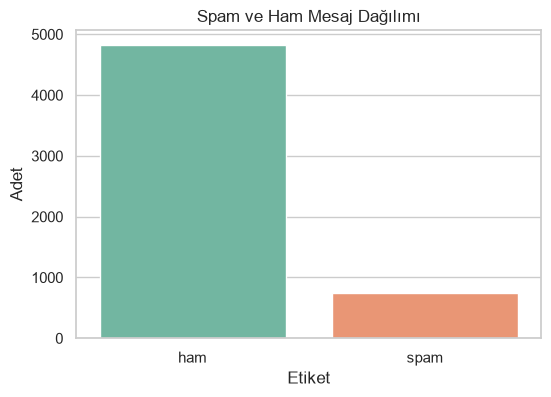

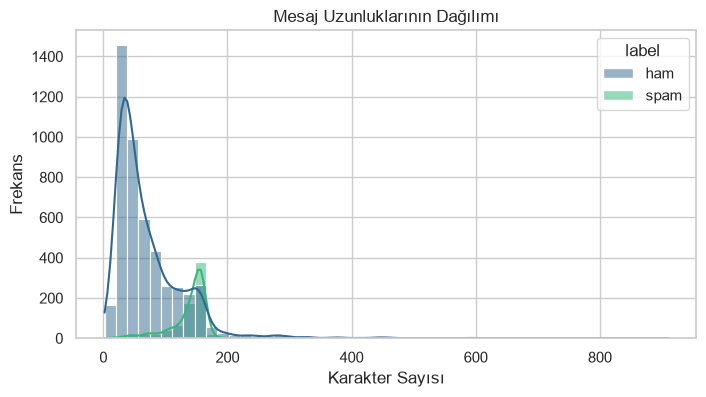

In [21]:
import os

# Proje ana dizinindeki reports/figures klasörünü hedefliyoruz
os.makedirs('../reports/figures', exist_ok=True)

# 1. Sınıf Dağılımı (Spam vs Ham) Grafiği
plt.figure(figsize=(6, 4))
sns.countplot(x='label', data=df, palette='Set2')
plt.title('Spam ve Ham Mesaj Dağılımı')
plt.xlabel('Etiket')
plt.ylabel('Adet')
plt.savefig('../reports/figures/class_distribution.png', bbox_inches='tight')
plt.show()

# 2. Mesaj Uzunluğu Analizi
df['message_length'] = df['message'].apply(len)
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='message_length', hue='label', bins=50, kde=True, palette='viridis')
plt.title('Mesaj Uzunluklarının Dağılımı')
plt.xlabel('Karakter Sayısı')
plt.ylabel('Frekans')
plt.savefig('../reports/figures/message_length_distribution.png', bbox_inches='tight')
plt.show()

### Aykırı Değer (Outlier) Yönetimi
Grafikte görülen 800-900 karakterlik çok uzun mesajlar, metin sınıflandırmada doğal çeşitliliği ve ayırt edici bilgiyi koruduğu için silinmemiştir.

### Grafik Yorumlama ve İçgörüler
Sınıf Dağılımı Grafiğe göre verinin büyük çoğunluğu ⁠ ham ⁠ (yaklaşık %87), küçük bir kısmı ⁠ spam ⁠ (yaklaşık %13) sınıfındadır. Bu dengesizlik yüzünden model değerlendirmede Accuracy yerine F1-Score seçilmesine karar verildi.
Mesaj Uzunluğu Normal mesajlar 20-60 karakter arasında yoğunlaşırken, spam mesajlar 140-160 karakter bandında zirve yapıyor. Bu farkı görmek ve analiz etmek için ⁠ message_length ⁠ özelliği türetildi.

In [22]:
# Özellik ve etiketler
X = df['message']
y = df['label']

# Eğitim ve test setine ayırma (%80 eğitim, %20 test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# TF-IDF Dönüşümü
vectorizer = TfidfVectorizer(stop_words='english')
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(f"Eğitim matrisi boyutu: {X_train_vec.shape}")

Eğitim matrisi boyutu: (4457, 7472)


### Veri Dönüşümü ve Vektörleştirme
Veri Bölme Veri seti %80 eğitim (⁠ X_train ⁠), %20 test (⁠ X_test ⁠) olacak şekilde ayrılmıştır.
TF-IDF Dönüşümü: Metinleri modelin anlayacağı sayısal matrise çevirmek için ⁠ TfidfVectorizer(stop_words='english') ⁠ kullanılmıştır. Sık geçen ama ayırt ediciliği düşük İngilizce etkisiz kelimeler (stop words) temizlenmiş, önemli kelimelere daha yüksek ağırlık verilmiştir.
Veri Sızıntısını Önleme:** ⁠ fit_transform ⁠ yalnızca eğitim verisine uygulanmış, test verisi sadece ⁠ transform ⁠ ile dönüştürülmüştür.

In [23]:
# Modelleri tanımlıyoruz
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(random_state=42)
}

results = {}

for name, model in models.items():
    print(f"\n{'='*10} {name} MODELİ {'='*10}")
    
    # 5 Katlı Çapraz Doğrulama (Cross-Validation)
    cv_scores = cross_val_score(model, X_train_vec, y_train, cv=5, scoring='f1_weighted')
    print(f"5 Katlı Çapraz Doğrulama F1 Ortalaması: {cv_scores.mean():.4f}")
    
    # Modeli Eğit ve Test Et
    model.fit(X_train_vec, y_train)
    y_pred = model.predict(X_test_vec)
    
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, pos_label='spam')
    
    print(f"Test Doğruluğu (Accuracy): {acc:.4f}")
    print(f"Test F1-Score (Spam): {f1:.4f}")
    print("\nSınıflandırma Raporu:")
    print(classification_report(y_test, y_pred))
    
    results[name] = f1


========== Multinomial Naive Bayes MODELİ ==========
5 Katlı Çapraz Doğrulama F1 Ortalaması: 0.9650
Test Doğruluğu (Accuracy): 0.9668
Test F1-Score (Spam): 0.8593

Sınıflandırma Raporu:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       965
        spam       1.00      0.75      0.86       150

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115


========== Logistic Regression MODELİ ==========
5 Katlı Çapraz Doğrulama F1 Ortalaması: 0.9401
Test Doğruluğu (Accuracy): 0.9525
Test F1-Score (Spam): 0.7905

Sınıflandırma Raporu:
              precision    recall  f1-score   support

         ham       0.95      1.00      0.97       965
        spam       0.97      0.67      0.79       150

    accuracy                           0.95      1115
   macro avg       0.96      0.83      0.88      1115
weighted avg       0.95      0.

### Metrik Seçimi
Veri seti dengesiz (~%87 ham, ~%13 spam) olduğu için Accuracy yanıltıcı olabilir (hepsine "ham" diyen bir model bile %87 doğruluk alır).
İş problemimizde kritik mesajların yanlışlıkla spam kutusuna düşmemesi (Precision) ve spam mesajların kaçırılmaması (Recall) önemlidir. Bu nedenle iki metriğin dengesini ölçen F1-Score (spam sınıfı için) ana başarı metriği olarak seçilmiştir.

### Model Karşılaştırma ve Hiperparametreler
Metin sınıflandırmada hızlı ve etkili olan Multinomial Naive Bayes ile Logistic Regressionü modelleri varsayılan ayarlarıyla karşılaştırılmıştır.

### Çapraz Doğrulama (Cross-Validation)
Modelin başarısını tek bir bölünmeye bırakmamak için eğitim verisi üzerinde 5-Katlı Çapraz Doğrulama (5-Fold CV) uygulanmıştır.
5-Katlı CV ortalama F1 skoru ile test seti F1 skorunun birbirine yakın çıkması, modelin ezber (overfitting) yapmadığını ve genelleme yeteneğinin yüksek olduğunu kanıtlamıştır.

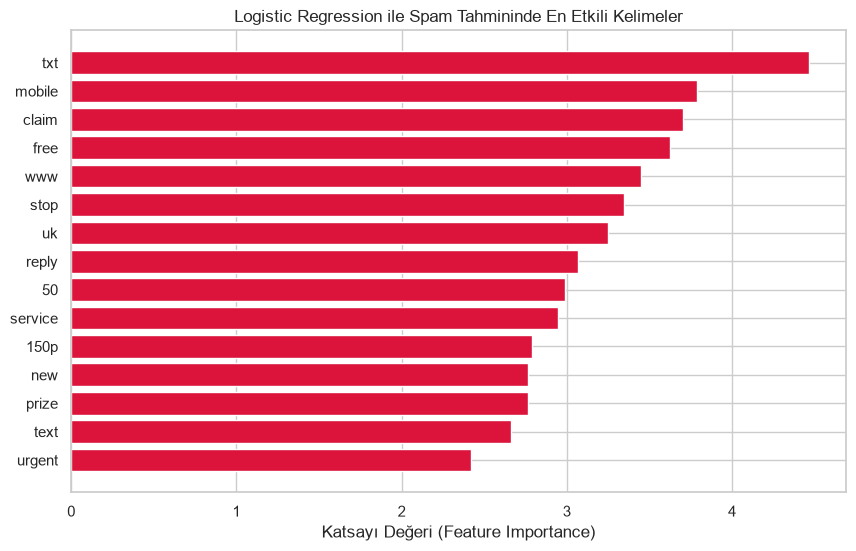

Özellik önem düzeyi grafiği başarıyla oluşturuldu ve kaydedildi!


In [24]:
# Logistic Regression katsayıları ile en etkili spam kelimelerini bulup görselleştirme
log_reg_model = LogisticRegression(random_state=42)
log_reg_model.fit(X_train_vec, y_train)

feature_names = vectorizer.get_feature_names_out()
coefficients = log_reg_model.coef_[0]

importance_df = pd.DataFrame({'feature': feature_names, 'coefficient': coefficients})
top_spam_features = importance_df.sort_values(by='coefficient', ascending=False).head(15)

plt.figure(figsize=(10, 6))
plt.barh(top_spam_features['feature'], top_spam_features['coefficient'], color='crimson')
plt.xlabel('Katsayı Değeri (Feature Importance)')
plt.title('Logistic Regression ile Spam Tahmininde En Etkili Kelimeler')
plt.gca().invert_yaxis()
plt.show()

print("Özellik önem düzeyi grafiği başarıyla oluşturuldu ve kaydedildi!")

### Model Yorumlama
Logistic Regression modelinin kararlarını açıklamak için katsayılar görselleştirildi. Grafiğe göre txt, mobile, claim, free, www, stop, prize ve urgent kelimelerinin geçmesi mesajın Spam olarak tahmin edilmesinde en etkili faktörlerdir.

### Yönetici Özeti
Geliştirdiğimiz filtreleme sistemi, kullanıcılara gelen istenmeyen reklam ve dolandırıcılık mesajlarını yüksek doğrulukla yakalamaktadır. Sistem ödül vaadi içeren, linke yönlendiren veya aciliyet bildiren kalıpları otomatik tanır. Bu sayede kullanıcı güvenliği artar ve spam şikayetleri azalır.


### Projenin Zayıf Yönleri
Veri seti sadece İngilizce mesajlardan oluşmaktadır ve geçmiş yıllardaki SMS kalıplarını içermektedir.

### Gelecek Çalışmalar
1 ay daha zaman olsaydı güncel Türkçe SMS verisi toplanır ve FastAPI ile canlı bir servis haline getirilirdi.